In [1]:
from pathlib import Path
import io

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

ANO = 2025
ANO_COMPARACAO = 2024
SEED = 40
R = 6_371_000

LAT_NYC = (40.49, 40.92)
LON_NYC = (-74.27, -73.68)

DADOS = Path("../data")
PROCESSADO = DADOS / "base-processada"
TABELAS = Path("../resultados/tabelas")
FIGURAS = Path("../resultados/figuras")
for pasta in (DADOS, PROCESSADO, TABELAS, FIGURAS):
    pasta.mkdir(parents=True, exist_ok=True)

## 1. Dados

### 1.1 Obtenção: API apenas se o arquivo local não existir
Cada ano é baixado da API Socrata (NYC Open Data) com o filtro de datas aplicado no servidor e salvo em `../data/colisoes_AAAA_bruto.csv`. Nas execuções seguintes o arquivo local é lido e a API não é chamada.

In [2]:
URL = "https://data.cityofnewyork.us/resource/h9gi-nx95.csv"
DTYPES = {"collision_id": str, "zip_code": str}

def baixar_ano(ano, tamanho_pagina=50_000):
    partes, offset = [], 0
    while True:
        params = {
            "$where": f"crash_date between '{ano}-01-01T00:00:00' and '{ano}-12-31T23:59:59'",
            "$order": "crash_date, collision_id",
            "$limit": tamanho_pagina,
            "$offset": offset,
        }
        r = requests.get(URL, params=params, timeout=120)
        r.raise_for_status()
        parte = pd.read_csv(io.StringIO(r.text), dtype=DTYPES, low_memory=False)
        partes.append(parte)
        print(f"offset {offset}: {len(parte)} linhas")
        if len(parte) < tamanho_pagina:
            break
        offset += tamanho_pagina
    return pd.concat(partes, ignore_index=True)

def carregar_ano(ano, forcar=False):
    caminho = DADOS / f"colisoes_{ano}_bruto.csv"
    if caminho.exists() and not forcar:
        print(f"Lendo {caminho} (sem chamar a API)")
        return pd.read_csv(caminho, dtype=DTYPES, low_memory=False)

    print(f"Baixando {ano} da API...")
    df = baixar_ano(ano)
    if df.empty:
        raise RuntimeError(f"A API não retornou nenhuma linha para {ano}; nada foi salvo.")

    tmp = caminho.with_name(caminho.name + ".tmp")
    df.to_csv(tmp, index=False)
    tmp.replace(caminho)
    print(f"Salvo em {caminho}")
    return df

bruto = carregar_ano(ANO)
print(bruto.shape)
print(bruto.columns.tolist())

Lendo ..\data\colisoes_2025_bruto.csv (sem chamar a API)
(85559, 29)
['crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'location', 'on_street_name', 'off_street_name', 'cross_street_name', 'number_of_persons_injured', 'number_of_persons_killed', 'number_of_pedestrians_injured', 'number_of_pedestrians_killed', 'number_of_cyclist_injured', 'number_of_cyclist_killed', 'number_of_motorist_injured', 'number_of_motorist_killed', 'contributing_factor_vehicle_1', 'contributing_factor_vehicle_2', 'contributing_factor_vehicle_3', 'contributing_factor_vehicle_4', 'contributing_factor_vehicle_5', 'collision_id', 'vehicle_type_code1', 'vehicle_type_code2', 'vehicle_type_code_3', 'vehicle_type_code_4', 'vehicle_type_code_5']


### 1.2 Validação da base bruta
Antes de limpar, confirmar que o ano está íntegro: os 12 meses presentes, nenhuma data fora do ano, nenhum ID repetido.

In [3]:
bruto["crash_date"] = pd.to_datetime(bruto["crash_date"], errors="coerce")

print("Colisões por mês:")
print(bruto["crash_date"].dt.month.value_counts().sort_index())
print("Fora de", ANO, ":", (bruto["crash_date"].dt.year != ANO).sum())
print("IDs duplicados:", bruto["collision_id"].duplicated().sum())
print("Datas inválidas:", bruto["crash_date"].isna().sum())
print(bruto.dtypes[["latitude", "longitude"]])

print("Tem localização mas não tem lat/lon:", (bruto["location"].notna() & bruto["latitude"].isna()).sum())
print("Tem lat/lon mas não tem localização:", (bruto["location"].isna() & bruto["latitude"].notna()).sum())

Colisões por mês:
crash_date
1     6482
2     5988
3     7035
4     6924
5     7636
6     7486
7     7415
8     6992
9     7538
10    7538
11    7148
12    7377
Name: count, dtype: int64
Fora de 2025 : 0
IDs duplicados: 0
Datas inválidas: 0
latitude     float64
longitude    float64
dtype: object
Tem localização mas não tem lat/lon: 0
Tem lat/lon mas não tem localização: 0


### 1.3 Limpeza e funil de linhas
Três filtros, cada um com uma razão ligada ao algoritmo:

1. **Remover latitude/longitude nulas:** sem posição não há como calcular distâncias.
2. **Remover coordenadas (0, 0):** a base usa zero como marcador de posição desconhecida (fica no oceano). Se ficassem, formariam um falso aglomerado.
3. **Manter só a caixa de Nova York:** garante que todos os pontos estão na cidade.

"Pontos únicos" é um **diagnóstico**, não um filtro: coordenadas repetidas são acidentes diferentes no mesmo local e carregam a informação de densidade, por isso não são removidas.

A mesma função é aplicada ao ano principal e ao ano de comparação.

In [4]:
def limpar_com_funil(d, rotulo):
    d = d.drop(columns=["location"], errors="ignore")
    d["crash_date"] = pd.to_datetime(d["crash_date"], errors="coerce")
    etapas = [(f"Linhas baixadas ({rotulo})", len(d))]

    d = d.dropna(subset=["latitude", "longitude"])
    etapas.append(("Com latitude e longitude", len(d)))

    d = d[(d["latitude"] != 0) & (d["longitude"] != 0)]
    etapas.append(("Sem coordenadas zero", len(d)))

    d = d[d["latitude"].between(*LAT_NYC) & d["longitude"].between(*LON_NYC)]
    etapas.append(("Dentro da caixa de NYC", len(d)))

    etapas.append(("Pontos únicos (lat, lon)",
                   d[["latitude", "longitude"]].drop_duplicates().shape[0]))

    funil = pd.DataFrame(etapas, columns=["etapa", "linhas"])
    funil["% do total"] = (funil["linhas"] / etapas[0][1] * 100).round(1)
    return d.reset_index(drop=True), funil

def limpar(d):
    return limpar_com_funil(d, "")[0]

df_limpo, funil_2025 = limpar_com_funil(bruto, ANO)

print(ANO); print(funil_2025.to_string(index=False))

df_limpo.to_csv(PROCESSADO / f"colisoes_{ANO}_limpo.csv", index=False)
funil_2025.to_csv(TABELAS / "funil_volumetria.csv", index=False)

2025
                   etapa  linhas  % do total
  Linhas baixadas (2025)   85559       100.0
Com latitude e longitude   84833        99.2
    Sem coordenadas zero   82918        96.9
  Dentro da caixa de NYC   82918        96.9
Pontos únicos (lat, lon)   44111        51.6


### 1.4 Diagnóstico das perdas
Duas perguntas: (1) as linhas removidas por "coordenada zero" são mesmo (0, 0)? (2) a perda está espalhada pelos bairros ou concentrada em algum? Se estivesse concentrada, a densidade dessa região seria subestimada.

In [5]:
com_coord = bruto[bruto["latitude"].notna()]
print(((com_coord.latitude == 0) & (com_coord.longitude == 0)).sum(), "em (0, 0)")
print(((com_coord.latitude == 0) ^ (com_coord.longitude == 0)).sum(), "com só um dos dois zero")

sem_coord = bruto["latitude"].isna() | (bruto["latitude"] == 0) | (bruto["longitude"] == 0)
print(bruto.assign(sem_coord=sem_coord)
           .groupby("borough", dropna=False)["sem_coord"].agg(["mean", "sum"]))

1915 em (0, 0)
0 com só um dos dois zero
                   mean  sum
borough                     
BRONX          0.032056  394
BROOKLYN       0.025457  680
MANHATTAN      0.041345  599
QUEENS         0.027839  608
STATEN ISLAND  0.023977   75
NaN            0.040141  285


## 2. Estrutura espacial dos dados

### 2.1 Quantos acidentes há por coordenada?
Muitos acidentes são geocodificados no mesmo cruzamento, então há coordenadas repetidas. Isso importa para o `min_samples`: **um ponto com `n ≥ min_samples` acidentes já é ponto central sozinho**, qualquer que seja o `eps`.
A tabela de cobertura mostra, para cada limiar, quanto da base já está em locais densos antes de somar vizinhos.

In [6]:
contagem = (df_limpo.groupby(["latitude", "longitude"])
                    .size().rename("n").reset_index())

print(contagem["n"].describe())
print(contagem["n"].value_counts().sort_index().head(10))

print()
for m in [3, 5, 10, 20, 50]:
    q = contagem[contagem["n"] >= m]
    print(f"n >= {m:>2}: {len(q):>5} pontos | {q['n'].sum():>6} acidentes "
          f"({q['n'].sum() / len(df_limpo):.1%} das linhas)")

count    44111.000000
mean         1.879758
std          2.320013
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        169.000000
Name: n, dtype: float64
n
1     30024
2      6472
3      2992
4      1585
5       937
6       587
7       359
8       271
9       203
10      140
Name: count, dtype: int64

n >=  3:  7615 pontos |  39950 acidentes (48.2% das linhas)
n >=  5:  3038 pontos |  24634 acidentes (29.7% das linhas)
n >= 10:   681 pontos |   9919 acidentes (12.0% das linhas)
n >= 20:    89 pontos |   2443 acidentes (2.9% das linhas)
n >= 50:     3 pontos |    274 acidentes (0.3% das linhas)


### 2.2 Locais com mais acidentes
Os pontos mais densos incluem **pontes e vias expressas**: nelas a coordenada representa um trecho longo, e não um cruzamento. Isso é um artefato de registro e será testado na seção 6.2.

In [7]:
lat, lon = contagem.loc[contagem["n"].idxmax(), ["latitude", "longitude"]]
topo = df_limpo[(df_limpo["latitude"] == lat) & (df_limpo["longitude"] == lon)]
print(topo["on_street_name"].value_counts(dropna=False).head())
print(topo["borough"].value_counts(dropna=False))
print(topo["crash_date"].dt.month.value_counts().sort_index())

rua = (df_limpo.groupby(["latitude", "longitude"])["on_street_name"]
       .agg(lambda s: s.dropna().mode().iat[0] if s.notna().any() else None)
       .rename("rua_mais_comum").reset_index())
print(contagem.nlargest(20, "n").merge(rua, on=["latitude", "longitude"]).to_string(index=False))

on_street_name
VERRAZANO BRIDGE UPPER    137
VERRAZANO BRIDGE LOWER     32
Name: count, dtype: int64
borough
BROOKLYN    126
NaN          43
Name: count, dtype: int64
crash_date
1      9
2     11
3     15
4     20
5     14
6     16
7     26
8     21
9      9
10     9
11    11
12     8
Name: count, dtype: int64
 latitude  longitude   n         rua_mais_comum
40.608757 -74.038086 169 VERRAZANO BRIDGE UPPER
40.604153 -74.051980  55 VERRAZANO BRIDGE UPPER
40.861866 -73.912740  50           W FORDHAM RD
40.675735 -73.896850  42       PENNSYLVANIA AVE
40.696033 -73.984530  42             TILLARY ST
40.696198 -73.988760  39               ADAMS ST
40.668507 -73.925606  35           EASTERN PKWY
40.795220 -73.921524  34      TRIBOROUGH BRIDGE
40.642540 -73.876520  33           BELT PARKWAY
40.658577 -73.890625  33       PENNSYLVANIA AVE
40.674854 -73.970780  33           FLATBUSH AVE
40.711220 -73.728264  33      CROSS ISLAND PKWY
40.795370 -73.921974  33      TRIBOROUGH BRIDGE
40.797370 -73.91

## 3. Escolha dos parâmetros

### 3.1 Gráfico de k-distância
Para cada ponto, a distância até o seu k-ésimo vizinho (com `k = min_samples`), em metros e com a fórmula de **haversine** (distância sobre a esfera, em radianos).

- Trecho colado em zero: pontos em coordenadas repetidas, que já têm k vizinhos no mesmo local.
- **Não há "joelho" nítido**: a densidade de acidentes é um contínuo ao longo da malha de ruas. Por isso o gráfico serve para **delimitar a faixa de `eps`**, e não para fixá-lo.
- A fração de pontos centrais para cada `eps` sai direto dos percentis.

k=5: mediana 58 m | p75 92 m | p90 141 m | % com distância 0: 29.7%
k=10: mediana 100 m | p75 155 m | p90 209 m | % com distância 0: 12.0%
k=20: mediana 165 m | p75 228 m | p90 299 m | % com distância 0: 2.9%

k=5: centrais por eps {50: '46%', 100: '79%', 150: '92%', 250: '99%', 400: '100%'} | p99: 272 m | máx: 1640 m
k=10: centrais por eps {50: '20%', 100: '50%', 150: '73%', 250: '95%', 400: '99%'} | p99: 406 m | máx: 2643 m
k=20: centrais por eps {50: '7%', 100: '19%', 150: '39%', 250: '82%', 400: '96%'} | p99: 595 m | máx: 2829 m


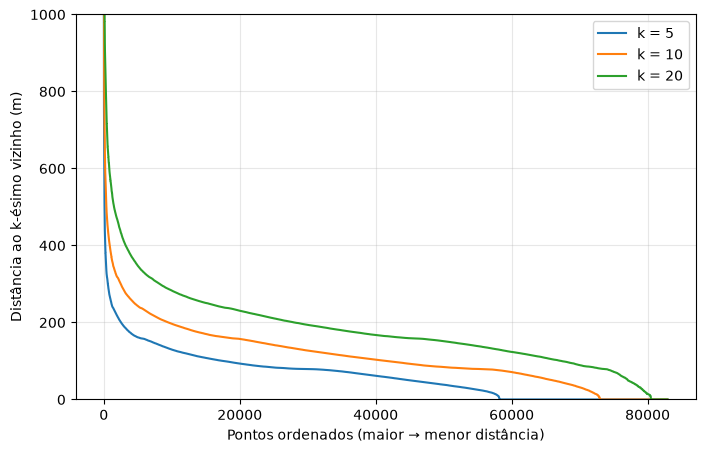

In [8]:
X = np.radians(df_limpo[["latitude", "longitude"]].to_numpy())

kdists = {}
fig, ax = plt.subplots(figsize=(8, 5))
for k in [5, 10, 20]:
    nn = NearestNeighbors(n_neighbors=k, metric="haversine", algorithm="ball_tree").fit(X)
    dist, _ = nn.kneighbors(X)
    d = dist[:, -1] * R
    kdists[k] = d
    ax.plot(np.sort(d)[::-1], label=f"k = {k}")
    print(f"k={k}: mediana {np.median(d):.0f} m | p75 {np.percentile(d, 75):.0f} m | "
          f"p90 {np.percentile(d, 90):.0f} m | % com distância 0: {(d == 0).mean():.1%}")

ax.set_ylim(0, 1000)
ax.set_xlabel("Pontos ordenados (maior → menor distância)")
ax.set_ylabel("Distância ao k-ésimo vizinho (m)")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIGURAS / "kdistancia.png", dpi=150, bbox_inches="tight")

print()
for k, d in kdists.items():
    frac = {e: f"{(d <= e).mean():.0%}" for e in [50, 100, 150, 250, 400]}
    print(f"k={k}: centrais por eps {frac} | p99: {np.percentile(d, 99):.0f} m | máx: {d.max():.0f} m")

### 3.2 Grade de `eps` × `min_samples`
O DBSCAN é ajustado sobre os **pontos únicos**, usando o número de acidentes de cada ponto como peso (`sample_weight`). O resultado de densidade é equivalente a usar todas as linhas, com menos memória.

O que observar: o **ruído** cai sempre que `eps` cresce; o **nº de clusters** sobe e depois desce (fusões); e o **% do maior cluster** dá um salto quando começa o *encadeamento* (clusters vizinhos se conectam em cadeia).

In [9]:
MIN_SAMPLES_GRADE = [5, 10, 20]
EPS_GRADE = [50, 100, 150, 250, 400]

Xp = np.radians(contagem[["latitude", "longitude"]].to_numpy())
w = contagem["n"].to_numpy()

linhas = []
for min_s in MIN_SAMPLES_GRADE:
    for eps_m in EPS_GRADE:
        lab = DBSCAN(eps=eps_m / R, min_samples=min_s,
                     metric="haversine", algorithm="ball_tree").fit(Xp, sample_weight=w).labels_
        tam = pd.Series(w[lab != -1]).groupby(lab[lab != -1]).sum()
        linhas.append({
            "min_samples": min_s, "eps_m": eps_m,
            "n_clusters": len(tam),
            "pct_ruido": round(w[lab == -1].sum() / w.sum() * 100, 1),
            "pct_maior_cluster": round(tam.max() / w.sum() * 100, 1) if len(tam) else 0,
            "tamanho_mediano": tam.median() if len(tam) else 0,
        })

grade = pd.DataFrame(linhas)
print(grade.to_string(index=False))
grade.to_csv(TABELAS / "grade_dbscan.csv", index=False)

 min_samples  eps_m  n_clusters  pct_ruido  pct_maior_cluster  tamanho_mediano
           5     50        4311       50.1                0.2              7.0
           5    100        2499       13.7               11.7              9.0
           5    150         829        4.7               36.2              9.0
           5    250         144        0.6               58.8             10.0
           5    400          25        0.1               92.9              9.0
          10     50        1171       76.2                0.2             13.0
          10    100        1620       35.7                3.7             17.0
          10    150         691       15.0               24.7             18.0
          10    250         117        2.3               57.4             18.0
          10    400          25        0.4               92.8             31.0
          20     50         234       91.6                0.2             26.0
          20    100         608       70.4          

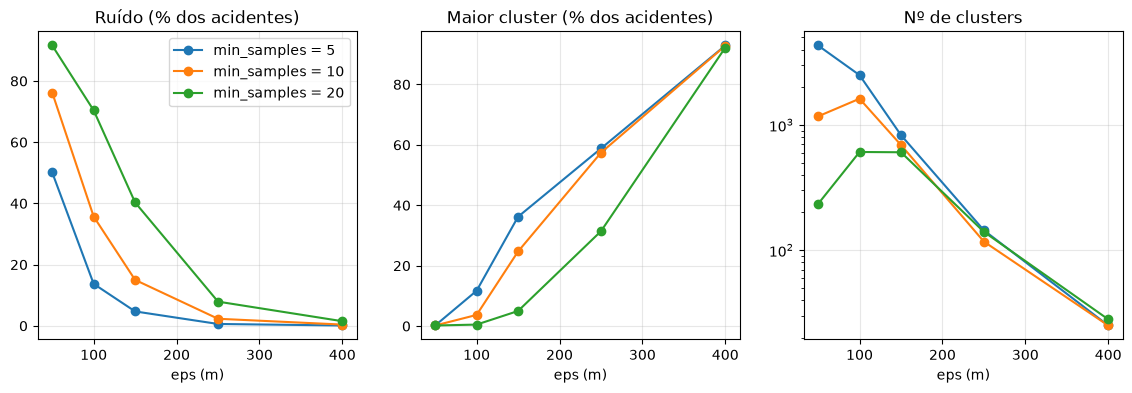

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for k, g in grade.groupby("min_samples"):
    axs[0].plot(g.eps_m, g.pct_ruido, marker="o", label=f"min_samples = {k}")
    axs[1].plot(g.eps_m, g.pct_maior_cluster, marker="o")
    axs[2].plot(g.eps_m, g.n_clusters, marker="o")
for ax, t in zip(axs, ["Ruído (% dos acidentes)", "Maior cluster (% dos acidentes)", "Nº de clusters"]):
    ax.set_title(t); ax.set_xlabel("eps (m)"); ax.grid(alpha=0.3)
axs[2].set_yscale("log")
axs[0].legend()
fig.savefig(FIGURAS / "grade_eps_minsamples.png", dpi=150, bbox_inches="tight")

## 4. Configurações escolhidas e mapas

Três configurações, escolhidas a partir da grade:

- **A** e **B:** ficam antes do encadeamento (o maior cluster ainda é pequeno). B é mais seletiva (exige mais acidentes por cluster).
- **C:** configuração de **contraste**, com `eps` maior, para mostrar o encadeamento.

`resumo_clusters` ajusta o DBSCAN e devolve os rótulos de cada ponto e uma tabela com uma linha por cluster (acidentes, pontos únicos, centro e extensão).

In [11]:
CONFIGS = {"A": (10, 100), "B": (20, 150), "C": (10, 250)}

def resumo_clusters(min_s, eps_m):
    lab = DBSCAN(eps=eps_m / R, min_samples=min_s, metric="haversine",
                 algorithm="ball_tree").fit(Xp, sample_weight=w).labels_
    ok = contagem.assign(cluster=lab)
    ok = ok[ok.cluster != -1].assign(wl=lambda d: d.latitude * d.n,
                                     wo=lambda d: d.longitude * d.n)
    r = ok.groupby("cluster").agg(
        acidentes=("n", "sum"), pontos_unicos=("n", "size"),
        lat_min=("latitude", "min"), lat_max=("latitude", "max"),
        lon_min=("longitude", "min"), lon_max=("longitude", "max"),
        wl=("wl", "sum"), wo=("wo", "sum"))
    r["lat"] = r.wl / r.acidentes
    r["lon"] = r.wo / r.acidentes
    r["extensao_m"] = np.hypot((r.lat_max - r.lat_min) * 111_000,
                               (r.lon_max - r.lon_min) * 111_000 * np.cos(np.radians(r.lat)))
    return lab, r.drop(columns=["wl", "wo"]).sort_values("acidentes", ascending=False)

labA, resA = resumo_clusters(*CONFIGS["A"])
labB, resB = resumo_clusters(*CONFIGS["B"])
labC, resC = resumo_clusters(*CONFIGS["C"])
LABELS = {"A": labA, "B": labB, "C": labC}

for nome, res in [("A", resA), ("B", resB), ("C", resC)]:
    print(f"{nome} {CONFIGS[nome]}: {len(res)} clusters | "
          f"clusters de 1 único ponto: {(res.pontos_unicos == 1).mean():.1%}")

A (10, 100): 1620 clusters | clusters de 1 único ponto: 1.5%
B (20, 150): 605 clusters | clusters de 1 único ponto: 0.5%
C (10, 250): 117 clusters | clusters de 1 único ponto: 2.6%


### 4.1 Mapas
Cinza-claro: ruído · cinza-escuro: clusters fora do top 10 · cores: os 10 maiores clusters de cada painel.
**A cor indica a posição no ranking dentro de cada painel**, e não o mesmo cluster entre os mapas.

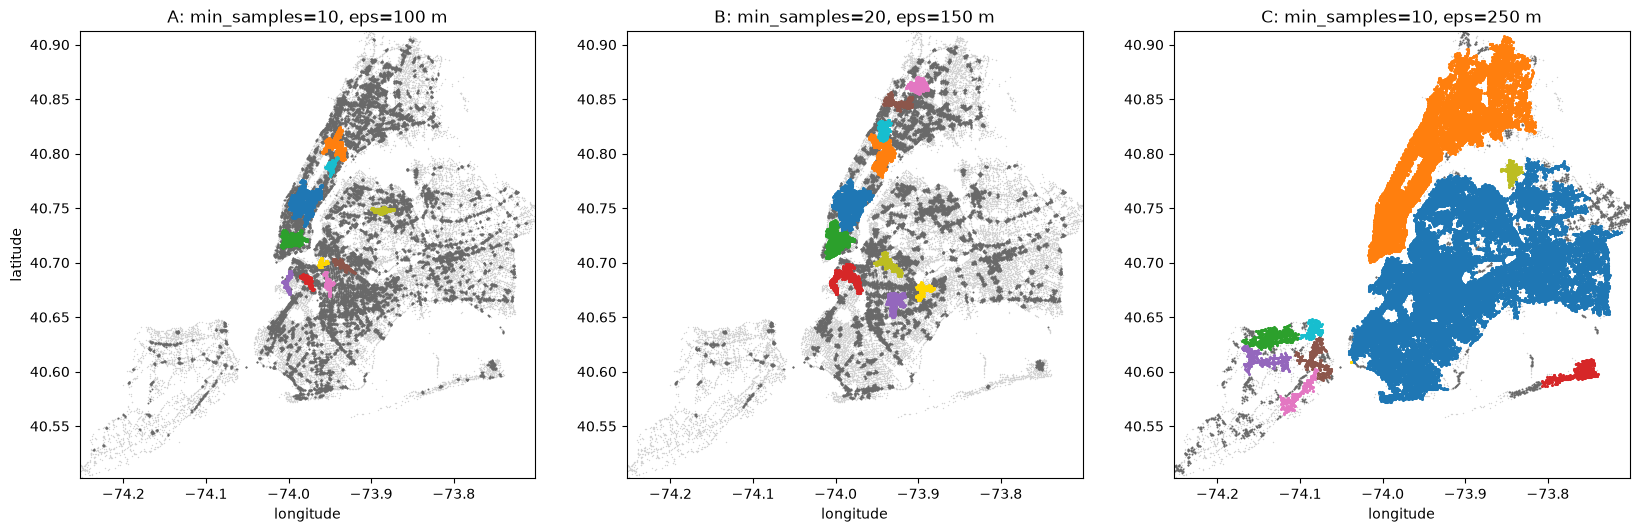

In [12]:
cores_top = [plt.cm.tab10(i) for i in (0, 1, 2, 3, 4, 5, 6, 8, 9)] + ["gold"]

def plotar(ax, lab, res, titulo, top=10):
    ruido = lab == -1
    top_ids = res.index[:top]
    outros = (~ruido) & (~np.isin(lab, top_ids))

    ax.scatter(contagem.longitude[ruido], contagem.latitude[ruido], s=1, c="lightgray", linewidths=0)
    ax.scatter(contagem.longitude[outros], contagem.latitude[outros], s=2, c="dimgray", linewidths=0)
    for cor, cid in zip(cores_top, top_ids):
        m = lab == cid
        ax.scatter(contagem.longitude[m], contagem.latitude[m], s=5, color=cor, linewidths=0)

    ax.set_title(titulo)
    ax.set_xlim(contagem.longitude.min(), contagem.longitude.max())
    ax.set_ylim(contagem.latitude.min(), contagem.latitude.max())
    ax.set_aspect(1 / np.cos(np.radians(40.73)))
    ax.set_xlabel("longitude")

fig, axs = plt.subplots(1, 3, figsize=(20, 8))
for ax, (nome, res) in zip(axs, [("A", resA), ("B", resB), ("C", resC)]):
    ms, eps = CONFIGS[nome]
    plotar(ax, LABELS[nome], res, f"{nome}: min_samples={ms}, eps={eps} m")
axs[0].set_ylabel("latitude")
fig.savefig(FIGURAS / "mapas_abc.png", dpi=150, bbox_inches="tight")

## 5. Métricas de avaliação

### 5.1 Silhouette
Compara a distância média dentro do próprio cluster com a distância até o cluster vizinho (de −1 a 1; maior é melhor).

- Calculado **só sobre pontos fora do ruído**, com distância haversine e amostra de 10 mil pontos, repetida com 5 sementes (média ± desvio).
- **Limitação:** o Silhouette favorece grupos compactos e separados; o DBSCAN encontra formas arbitrárias, como corredores de avenidas. Por isso é complementado por ruído, tamanho, mapas e estabilidade.
- Cada configuração avalia uma fração diferente da base (a que não é ruído); a comparação é entre os clusters encontrados.

In [13]:
def rotulos_por_linha(lab):
    m = contagem[["latitude", "longitude"]].assign(cluster=lab)
    return (df_limpo[["latitude", "longitude"]]
            .merge(m, on=["latitude", "longitude"], how="left")["cluster"].to_numpy())

def silhouette_amostra(lab_linhas, n=10_000, repet=5):
    ok = lab_linhas != -1
    Xk, yk = X[ok], lab_linhas[ok]
    if len(np.unique(yk)) < 2:
        return np.nan, np.nan
    v = [silhouette_score(Xk, yk, metric="haversine",
                          sample_size=min(n, len(yk)), random_state=SEED + i)
         for i in range(repet)]
    return np.mean(v), np.std(v)

linhas = []
for nome, (ms, eps) in CONFIGS.items():
    lin = rotulos_por_linha(LABELS[nome])
    assert len(lin) == len(df_limpo)
    media, dp = silhouette_amostra(lin)
    g = grade[(grade.min_samples == ms) & (grade.eps_m == eps)].iloc[0]
    linhas.append({"config": nome, "min_samples": ms, "eps_m": eps,
                   "n_clusters": int(g.n_clusters), "pct_ruido": g.pct_ruido,
                   "pct_maior_cluster": g.pct_maior_cluster,
                   "silhouette_media": round(media, 3), "silhouette_dp": round(dp, 3)})

tabela_metricas = pd.DataFrame(linhas)
print(tabela_metricas.to_string(index=False))
tabela_metricas.to_csv(TABELAS / "metricas_abc.csv", index=False)

config  min_samples  eps_m  n_clusters  pct_ruido  pct_maior_cluster  silhouette_media  silhouette_dp
     A           10    100        1620       35.7                3.7             0.271          0.006
     B           20    150         605       40.3                5.0             0.191          0.006
     C           10    250         117        2.3               57.4            -0.584          0.013


### 5.2 Extensão dos clusters
O `eps` limita a distância entre **vizinhos conectados**, e não o tamanho do cluster: uma cadeia de pontos ao longo de uma avenida pode se estender por quilômetros.
Como a mediana é por cluster e o Silhouette é por ponto, também se mostra a extensão **ponderada pelo nº de acidentes**. Clusters mais alongados ajudam a explicar um Silhouette menor.

In [14]:
def ext_stats(res):
    tot = res.acidentes.sum()
    return pd.Series({
        "extensao_mediana_m": round(res.extensao_m.median()),
        "extensao_media_pond_m": round(np.average(res.extensao_m, weights=res.acidentes)),
        "pct_acid_clusters_>2km": round(res.loc[res.extensao_m > 2000, "acidentes"].sum() / tot * 100, 1)})

ext = pd.DataFrame({"A": ext_stats(resA), "B": ext_stats(resB), "C": ext_stats(resC)}).T
ext.index.name = "config"
print(ext.to_string())

        extensao_mediana_m  extensao_media_pond_m  pct_acid_clusters_>2km
config                                                                   
A                    241.0                 1100.0                    15.5
B                    454.0                 2106.0                    37.6
C                    564.0                31478.0                    96.3


### 5.3 DBCV (Density-Based Clustering Validation)

O Silhouette compara distâncias médias e favorece grupos compactos e arredondados, o que é uma limitação para o DBSCAN, que encontra corredores e formas arbitrárias. O **DBCV** foi proposto para avaliar partições baseadas em densidade (varia de −1 a 1; **maior é melhor**).

Para cada cluster $C_i$, com $n_i$ pontos em $m$ dimensões ($m = 2$, por usarmos latitude e longitude):

- **Distância-núcleo:** $a(p)=\left(\dfrac{\sum_{q\in C_i,\,q\neq p}\,d(p,q)^{-m}}{n_i-1}\right)^{-1/m}$, que é pequena em regiões densas.
- **Alcançabilidade mútua:** $d_{mreach}(p,q)=\max\{a(p),\,a(q),\,d(p,q)\}$. Sobre ela se constrói a árvore geradora mínima (MST) de cada cluster.
- **Esparsidade** $DSPC(C_i)$: maior aresta da MST (considerando só os nós internos). Mede o quão "ralo" é o ponto mais fraco do cluster.
- **Separação** $DSC(C_i)$: menor alcançabilidade mútua entre o cluster e qualquer outro.
- **Validade do cluster:** $V(C_i)=\dfrac{DSC(C_i)-DSPC(C_i)}{\max\{DSC(C_i),\,DSPC(C_i)\}}$. É positiva quando o cluster é mais denso por dentro do que separado dos vizinhos.
- **DBCV:** média dos $V(C_i)$ ponderada pelo tamanho de cada cluster.

**Adaptações necessárias para esta base**:

1. **Distância em metros.** A implementação usa distância euclidiana, então as coordenadas são projetadas em metros (projeção equirretangular centrada em NYC). Em uma área de ~50 km a distorção é desprezível.
2. **Pontos únicos, e não linhas.** A fórmula usa $1/d$, que não existe para $d=0$ (acidentes na mesma coordenada). Por isso o DBCV é calculado sobre as coordenadas únicas. Consequência: ele **não usa o peso** (nº de acidentes por ponto) e mede a geometria espacial dos locais.
3. **Ruído fora do cálculo.** Como no Silhouette, só entram pontos que pertencem a clusters. O ruído já é reportado à parte.
4. **Clusters com menos de 3 pontos únicos são ignorados.** Um cluster de um único local (frequente com `min_samples` alto, pois um ponto com muitos acidentes já é núcleo sozinho) não tem geometria para medir densidade. A tabela informa quanto dos acidentes ficou de fora por isso.
5. **Janelas espaciais.** O cálculo exige a matriz de distâncias completa (memória proporcional a $n^2$), inviável para ~44 mil pontos. Avaliamos **5 janelas de 5 km × 5 km**, uma por distrito, iguais para todas as configurações. Os clusters são **recortados** pela janela (não descartados), para que o encadeamento de C continue visível. Pontos na borda têm separação ligeiramente superestimada.

In [15]:
from hdbscan.validity import validity_index

LAT_REF = 40.73
xy = np.column_stack([
    R * np.radians(contagem.longitude) * np.cos(np.radians(LAT_REF)),
    R * np.radians(contagem.latitude),
])

JANELAS = {
    "Manhattan (Midtown)": (40.754, -73.985),
    "Brooklyn":            (40.680, -73.950),
    "Queens (Jamaica)":    (40.700, -73.800),
    "Bronx":               (40.850, -73.890),
    "Staten Island (Costa Norte)": (40.630, -74.100),
}
SEMI_LADO_M = 2_500
MIN_PONTOS_CLUSTER = 3
MAX_PONTOS = 8_000

def dbcv_janela(lab, centro, semi_lado=SEMI_LADO_M):
    lat_c, lon_c = centro
    dlat = np.degrees(semi_lado / R)
    dlon = np.degrees(semi_lado / (R * np.cos(np.radians(lat_c))))
    dentro = (contagem.latitude.between(lat_c - dlat, lat_c + dlat)
              & contagem.longitude.between(lon_c - dlon, lon_c + dlon)).to_numpy()

    ok = dentro & (lab != -1)
    ids, cont = np.unique(lab[ok], return_counts=True)
    validos = ids[cont >= MIN_PONTOS_CLUSTER]
    ok &= np.isin(lab, validos)

    info = {"pontos_janela": int(dentro.sum()),
            "pontos_avaliados": int(ok.sum()),
            "clusters_avaliados": len(validos),
            "pct_acid_avaliados": round(w[ok].sum() / max(w[dentro].sum(), 1) * 100, 1)}

    if len(validos) < 2 or ok.sum() > MAX_PONTOS:
        return np.nan, info
    y = np.unique(lab[ok], return_inverse=True)[1]
    try:
        return validity_index(xy[ok], y, metric="euclidean"), info
    except ValueError:
        return np.nan, info

linhas = []
for nome, (ms, eps) in CONFIGS.items():
    for janela, centro in JANELAS.items():
        v, info = dbcv_janela(LABELS[nome], centro)
        linhas.append({"config": nome, "min_samples": ms, "eps_m": eps,
                       "janela": janela, "dbcv": v, **info})

dbcv_janelas = pd.DataFrame(linhas)
print(dbcv_janelas.round({"dbcv": 3}).to_string(index=False))
dbcv_janelas.to_csv(TABELAS / "dbcv_por_janela.csv", index=False)

tabela_dbcv = (dbcv_janelas.groupby("config")
               .agg(dbcv_media=("dbcv", "mean"), dbcv_dp_janelas=("dbcv", "std"),
                    janelas_validas=("dbcv", "count"),
                    pct_acid_avaliados=("pct_acid_avaliados", "mean"))
               .round(3))
print(); print(tabela_dbcv.to_string())
tabela_dbcv.to_csv(TABELAS / "dbcv_resumo.csv")

config  min_samples  eps_m                      janela   dbcv  pontos_janela  pontos_avaliados  clusters_avaliados  pct_acid_avaliados
     A           10    100         Manhattan (Midtown) -0.465           2571              2162                  52                88.8
     A           10    100                    Brooklyn  0.042           2459              1851                 130                84.2
     A           10    100            Queens (Jamaica)  0.213           1923               863                  78                58.2
     A           10    100                       Bronx  0.127           2510              1532                 110                71.7
     A           10    100 Staten Island (Costa Norte)  0.612            768               132                  15                22.6
     B           20    150         Manhattan (Midtown) -0.541           2571              2165                  16                88.2
     B           20    150                    Brooklyn 

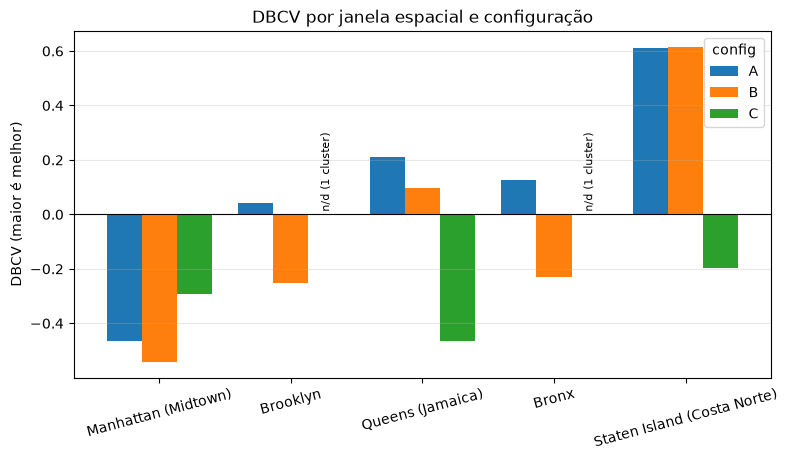

In [16]:
piv = (dbcv_janelas.pivot(index="janela", columns="config", values="dbcv")
       .loc[list(JANELAS)])
n_cl = (dbcv_janelas.pivot(index="janela", columns="config", values="clusters_avaliados")
        .loc[list(JANELAS)])

ax = piv.plot.bar(figsize=(9, 4.5), rot=15, width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("DBCV (maior é melhor)")
ax.set_xlabel("")
ax.set_title("DBCV por janela espacial e configuração")
ax.grid(alpha=0.3, axis="y")

larg = 0.8 / len(piv.columns)
for i, jan in enumerate(piv.index):
    for j, cfg in enumerate(piv.columns):
        if np.isnan(piv.loc[jan, cfg]):
            x = i - 0.4 + (j + 0.5) * larg
            ax.text(x, 0.01, f"n/d ({int(n_cl.loc[jan, cfg])} cluster)",
                    rotation=90, ha="center", va="bottom", fontsize=8)

ax.figure.savefig(FIGURAS / "dbcv_por_janela.png", dpi=150, bbox_inches="tight")

## 6. Robustez dos resultados

### 6.1 Estabilidade entre 2024 e 2025
As mesmas configurações são aplicadas a 2024. Pergunta: **os acidentes agrupados em um ano ficam perto de pontos agrupados no outro?**

- `cobertura_25_em_24`: % dos acidentes agrupados em 2025 a até `eps` metros de algum ponto agrupado em 2024 (e vice-versa).
- `base_ruido_25_em_24`: o **controle**. Mesma conta para os acidentes que em 2025 foram ruído. A estabilidade só é evidente se a cobertura dos clusters for bem maior que a do ruído.
- Mede **proximidade**, não identidade de clusters (um cluster pode se dividir ou se fundir e a cobertura continuar alta).

In [17]:
CONFIGS_ROBUSTEZ = {k: v for k, v in CONFIGS.items() if k in ("A", "B")}

bruto_comp = carregar_ano(ANO_COMPARACAO)
df24, funil_2024 = limpar_com_funil(bruto_comp, ANO_COMPARACAO)

def ajustar(d, min_s, eps_m):
    c = d.groupby(["latitude", "longitude"]).size().rename("n").reset_index()
    lab = DBSCAN(eps=eps_m / R, min_samples=min_s, metric="haversine",
                 algorithm="ball_tree").fit(np.radians(c[["latitude", "longitude"]]),
                                            sample_weight=c.n).labels_
    return c.assign(cluster=lab)

def cobertura(origem, alvo, eps_m):
    nn = NearestNeighbors(n_neighbors=1, metric="haversine", algorithm="ball_tree"
                          ).fit(np.radians(alvo[["latitude", "longitude"]]))
    dist, _ = nn.kneighbors(np.radians(origem[["latitude", "longitude"]]))
    return origem.loc[dist[:, 0] * R <= eps_m, "n"].sum() / origem.n.sum() * 100

print("Linhas válidas", ANO_COMPARACAO, ":", len(df24), "|", ANO, ":", len(df_limpo))

linhas = []
for nome, (ms, eps) in CONFIGS_ROBUSTEZ.items():
    c25 = ajustar(df_limpo, ms, eps)
    c24 = ajustar(df24, ms, eps)
    a25, a24 = c25[c25.cluster != -1], c24[c24.cluster != -1]
    ruido25 = c25[c25.cluster == -1]
    tam24 = a24.groupby("cluster").n.sum()
    linhas.append({
        "config": nome,
        "clusters_2025": a25.cluster.nunique(),
        "clusters_2024": len(tam24),
        "ruido_2024_%": round(c24[c24.cluster == -1].n.sum() / c24.n.sum() * 100, 1),
        "maior_cluster_2024_%": round(tam24.max() / c24.n.sum() * 100, 1),
        "cobertura_25_em_24_%": round(cobertura(a25, a24, eps), 1),
        "cobertura_24_em_25_%": round(cobertura(a24, a25, eps), 1),
        "base_ruido_25_em_24_%": round(cobertura(ruido25, a24, eps), 1),
    })

estab = pd.DataFrame(linhas)
print(estab.to_string(index=False))
estab.to_csv(TABELAS / "estabilidade_2024_2025.csv", index=False)

Lendo ..\data\colisoes_2024_bruto.csv (sem chamar a API)
Linhas válidas 2024 : 83697 | 2025 : 82918
config  clusters_2025  clusters_2024  ruido_2024_%  maior_cluster_2024_%  cobertura_25_em_24_%  cobertura_24_em_25_%  base_ruido_25_em_24_%
     A           1620           1662          35.1                   3.7                  87.4                  86.9                   27.1
     B            605            592          40.4                   4.1                  90.5                  91.0                   28.2


### 6.2 Sensibilidade a locais com muitos acidentes

Na seção 2.2 vimos que os pontos mais densos são, em boa parte, **pontes e vias expressas**, onde uma única coordenada representa um trecho longo. Como o DBSCAN usa o nº de acidentes de cada coordenada como peso, uma coordenada com `n ≥ min_samples` já é ponto central sozinha: esses locais funcionam como **âncoras** e podem sustentar ou conectar clusters.

Teste: remover esses locais, reajustar as configurações A e B e comparar com o ajuste da base completa. Cenários:

- **Um a um:** cada um dos `TOP_K` locais com mais acidentes removido isoladamente.
- **Verrazzano:** a ponte Verrazzano-Narrows (duas coordenadas para uma ponte de vários quilômetros, um artefato de geocodificação), removida em conjunto.
- **Todos juntos:** os `TOP_K` locais removidos de uma vez.

Medidas, sempre nos pontos que existem nas duas versões:

- **ARI** (índice de Rand ajustado): concordância entre as duas partições (1 = idênticas). O ruído (`-1`) conta como um grupo, então parte da variação do ARI vem de pontos que viram ruído ou saem dele.
- **`% acid. que trocaram ruído ↔ cluster`:** fração dos acidentes dos pontos comuns que entrou ou saiu de algum cluster. É mais fácil de interpretar que o ARI.
- **Nº de clusters, % de ruído e % do maior cluster:** calculados sobre a base restante.

Leitura: ARI próximo de 1 e poucas trocas indicam que o resultado **não depende** daquele local. Uma queda grande indica que o local ancorava ou conectava clusters.

In [18]:
TOP_K = 10

top = (contagem.nlargest(TOP_K, "n")
       .merge(rua, on=["latitude", "longitude"], how="left")
       .reset_index(drop=True))

VERRAZZANO = [(40.608757, -74.038086), (40.604153, -74.051980)]

def mascara(d, coords):
    m = np.zeros(len(d), dtype=bool)
    for la, lo in coords:
        m |= (d.latitude.round(6) == round(la, 6)) & (d.longitude.round(6) == round(lo, 6))
    return m

CENARIOS = {"Verrazzano (2 coordenadas)": VERRAZZANO}
for i, r in top.iterrows():
    CENARIOS[f"#{i + 1} {r.rua_mais_comum} ({int(r.n)} acid.)"] = [(r.latitude, r.longitude)]
CENARIOS[f"Top {TOP_K} juntos"] = list(zip(top.latitude, top.longitude))

def metricas(c):
    tot = c.n.sum()
    tam = c[c.cluster != -1].groupby("cluster").n.sum()
    return {"n_clusters": len(tam),
            "pct_ruido": round(c[c.cluster == -1].n.sum() / tot * 100, 1),
            "pct_maior_cluster": round(tam.max() / tot * 100, 1)}

base = {nome: ajustar(df_limpo, ms, eps) for nome, (ms, eps) in CONFIGS_ROBUSTEZ.items()}

linhas = []
for nome in CONFIGS_ROBUSTEZ:
    linhas.append({"config": nome, "cenario": "Base completa", "acid_removidos": 0,
                   "pct_base_removida": 0.0, **metricas(base[nome]),
                   "ARI_vs_base": 1.0, "pct_acid_trocaram": 0.0})

for rotulo, coords in CENARIOS.items():
    m = mascara(df_limpo, coords)
    df_sem = df_limpo[~m]
    for nome, (ms, eps) in CONFIGS_ROBUSTEZ.items():
        c_sem = ajustar(df_sem, ms, eps)
        comum = base[nome].merge(c_sem, on=["latitude", "longitude"], suffixes=("_com", "_sem"))
        troca = (comum.cluster_com == -1) != (comum.cluster_sem == -1)
        linhas.append({
            "config": nome, "cenario": rotulo,
            "acid_removidos": int(m.sum()), "pct_base_removida": round(m.mean() * 100, 2),
            **metricas(c_sem),
            "ARI_vs_base": round(adjusted_rand_score(comum.cluster_com, comum.cluster_sem), 4),
            "pct_acid_trocaram": round(np.average(troca, weights=comum.n_com) * 100, 2),
        })

sens = (pd.DataFrame(linhas)
          .sort_values(["config", "ARI_vs_base"], ascending=[True, False]))
print(sens.to_string(index=False))
sens.to_csv(TABELAS / "sensibilidade_locais.csv", index=False)

config                               cenario  acid_removidos  pct_base_removida  n_clusters  pct_ruido  pct_maior_cluster  ARI_vs_base  pct_acid_trocaram
     A                         Base completa               0               0.00        1620       35.7                3.7       1.0000               0.00
     A            Verrazzano (2 coordenadas)             224               0.27        1620       35.8                3.7       1.0000               0.00
     A #1 VERRAZANO BRIDGE UPPER (169 acid.)             169               0.20        1620       35.8                3.7       1.0000               0.00
     A  #2 VERRAZANO BRIDGE UPPER (55 acid.)              55               0.07        1620       35.7                3.7       1.0000               0.00
     A            #3 W FORDHAM RD (50 acid.)              50               0.06        1620       35.7                3.7       1.0000               0.00
     A        #4 PENNSYLVANIA AVE (42 acid.)              42               0

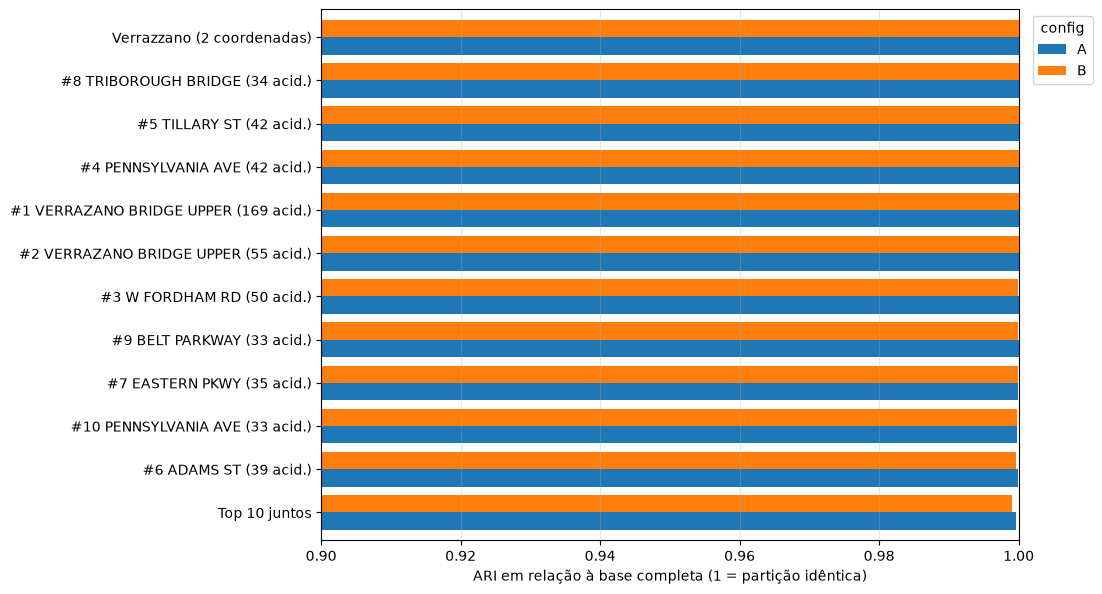

In [19]:
pv = sens[sens.cenario != "Base completa"].pivot(index="cenario", columns="config", values="ARI_vs_base")
pv = pv.loc[pv.min(axis=1).sort_values().index]          # mais sensíveis embaixo
ax = pv.plot.barh(figsize=(9, 0.45 * len(pv) + 1.5), width=0.8)
ax.set_xlim(min(0.9, pv.min().min() - 0.01), 1.0)
ax.set_xlabel("ARI em relação à base completa (1 = partição idêntica)")
ax.set_ylabel("")
ax.grid(alpha=0.3, axis="x")
ax.legend(title="config", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.figure.savefig(FIGURAS / "sensibilidade_locais.png", dpi=150, bbox_inches="tight")

## 7. Interpretação dos clusters

### 7.1 Maiores clusters e vias envolvidas
Para cada um dos maiores clusters: tamanho, centro, extensão, bairro mais frequente e as três vias mais comuns.
Os clusters costumam ser **corredores** que misturam vias expressas e ruas urbanas, e não pontos isolados.
O bairro vem da coluna `borough`, que tem valores ausentes; use-a só para descrever.

In [20]:
def tabela_top(lab, res, n=10):
    mapa = contagem[["latitude", "longitude"]].assign(cluster=lab)
    tmp = df_limpo.merge(mapa, on=["latitude", "longitude"], how="left")
    tmp = tmp[tmp["cluster"] != -1].astype({"cluster": int})

    vias = (tmp.groupby("cluster")["on_street_name"]
               .agg(lambda s: s.value_counts().head(3).index.tolist()))
    boro = (tmp.groupby("cluster")["borough"]
               .agg(lambda s: s.mode().iat[0] if s.notna().any() else None))

    out = res.head(n).copy()
    out["pct_dos_acidentes"] = (out["acidentes"] / len(df_limpo) * 100).round(1)
    out["borough"] = boro
    out["vias_principais"] = vias
    return out[["acidentes", "pct_dos_acidentes", "pontos_unicos", "lat", "lon",
                "extensao_m", "borough", "vias_principais"]]

top_A = tabela_top(labA, resA, n=10)
top_B = tabela_top(labB, resB, n=10)
print("A"); print(top_A.round({"lat": 5, "lon": 5, "extensao_m": 0}).to_string())
print(); print("B"); print(top_B.round({"lat": 5, "lon": 5, "extensao_m": 0}).to_string())
top_A.to_csv(TABELAS / "top10_clusters_A.csv")
top_B.to_csv(TABELAS / "top10_clusters_B.csv")

A
         acidentes  pct_dos_acidentes  pontos_unicos       lat       lon  extensao_m    borough                                                vias_principais
cluster                                                                                                                                                       
993           3100                3.7           1377  40.75595 -73.98130      5780.0  MANHATTAN                                        [2 AVE, 3 AVE, W 42 ST]
1291          1324                1.6            589  40.80748 -73.94222      4095.0  MANHATTAN              [E 125 ST, W 125 ST, ADAM CLAYTON POWELL JR BLVD]
868           1259                1.5            661  40.72101 -73.99550      3246.0  MANHATTAN                          [CANAL ST, DELANCEY ST, E HOUSTON ST]
527            564                0.7            217  40.68318 -73.97686      2147.0   BROOKLYN                        [FLATBUSH AVE, ATLANTIC AVE, FULTON ST]
502            456                0.5       

### 7.2 Gravidade dos acidentes por cluster (configuração A)
Descritivo: feridos, mortos e % de acidentes com ferido em cada cluster, comparados com a cidade toda e com o ruído. A margem de erro (95%) mostra se a diferença entre clusters é distinguível do acaso.
**Não é uma medida de risco:** a base não traz volume de tráfego nem de pedestres (exposição).

In [21]:
COL_FER, COL_MORT = "number_of_persons_injured", "number_of_persons_killed"
COL_PED, COL_CIC = "number_of_pedestrians_injured", "number_of_cyclist_injured"

def gravidade_por_cluster(lab):
    mapa = contagem[["latitude", "longitude"]].assign(cluster=lab)
    d = df_limpo.merge(mapa, on=["latitude", "longitude"], how="left")
    assert len(d) == len(df_limpo)

    cols = [COL_FER, COL_MORT, COL_PED, COL_CIC]
    d[cols] = d[cols].fillna(0)
    d["com_ferido"] = d[COL_FER] > 0
    d["ped_cic_feridos"] = d[COL_PED] + d[COL_CIC]

    g = d.groupby("cluster").agg(
        acidentes=("collision_id", "size"),
        feridos=(COL_FER, "sum"),
        mortos=(COL_MORT, "sum"),
        ped_cic_feridos=("ped_cic_feridos", "sum"),
        acid_com_ferido=("com_ferido", "sum"),
    )
    g["feridos_por_100_acid"] = (g.feridos / g.acidentes * 100).round(1)
    g["pct_acid_com_ferido"] = (g.acid_com_ferido / g.acidentes * 100).round(1)
    p = g.acid_com_ferido / g.acidentes
    g["margem_95"] = (1.96 * np.sqrt(p * (1 - p) / g.acidentes) * 100).round(1)
    g["pct_feridos_ped_cic"] = (g.ped_cic_feridos / g.feridos.replace(0, np.nan) * 100).round(1)
    return g

gA = gravidade_por_cluster(labA)

chk = gA.drop(index=-1).acidentes.reindex(resA.index)
assert (chk.values == resA.acidentes.values).all(), "contagens divergem de resA"

def linha_ref(nome, g):
    t = g.sum(numeric_only=True)
    return pd.Series({
        "acidentes": t.acidentes, "feridos": t.feridos, "mortos": t.mortos,
        "feridos_por_100_acid": round(t.feridos / t.acidentes * 100, 1),
        "pct_acid_com_ferido": round(t.acid_com_ferido / t.acidentes * 100, 1)}, name=nome)

ref = pd.DataFrame([
    linha_ref("Cidade toda", gA),
    linha_ref("Só clusters", gA.drop(index=-1)),
    linha_ref("Ruído", gA.loc[[-1]]),
])
print(ref.to_string())

t1 = top_A[["borough", "acidentes"]].join(
    gA[["feridos", "mortos", "feridos_por_100_acid",
        "pct_acid_com_ferido", "margem_95", "pct_feridos_ped_cic"]])
print(); print(t1.to_string())

MIN_ACID = 100
t2 = (gA.drop(index=-1).query("acidentes >= @MIN_ACID")
        .sort_values("feridos_por_100_acid", ascending=False)
        .join(top_A[["borough"]], how="left"))
cols_t2 = ["acidentes", "feridos", "mortos", "feridos_por_100_acid", "pct_acid_com_ferido", "margem_95"]
print(); print(f"{len(t2)} clusters com >= {MIN_ACID} acidentes")
print(t2.head(10)[cols_t2].to_string())
print(t2.tail(5)[cols_t2].to_string())

ref.to_csv(TABELAS / "gravidade_referencias_A.csv")
t1.to_csv(TABELAS / "gravidade_top10_volume_A.csv")
t2.to_csv(TABELAS / "gravidade_clusters_A.csv")

             acidentes  feridos  mortos  feridos_por_100_acid  pct_acid_com_ferido
Cidade toda    82918.0  48406.0   215.0                  58.4                 43.8
Só clusters    53322.0  32292.0   133.0                  60.6                 45.4
Ruído          29596.0  16114.0    82.0                  54.4                 40.9

           borough  acidentes  feridos  mortos  feridos_por_100_acid  pct_acid_com_ferido  margem_95  pct_feridos_ped_cic
cluster                                                                                                                  
993      MANHATTAN       3100     1605       8                  51.8                 46.2        1.8                 59.7
1291     MANHATTAN       1324      705       4                  53.2                 42.1        2.7                 40.9
868      MANHATTAN       1259      588       2                  46.7                 39.3        2.7                 49.3
527       BROOKLYN        564      324       1           

## 8. Quadro final de comparação
Reúne em uma só tabela as métricas de qualidade (Silhouette), a estrutura (ruído, nº e tamanho dos clusters), a extensão e a estabilidade. É a base para justificar a configuração escolhida.
A configuração C não tem estabilidade calculada (serve apenas de contraste).

In [22]:
final = (tabela_metricas.set_index("config")
        .join(ext)
        .join(estab.set_index("config")[["cobertura_25_em_24_%", "cobertura_24_em_25_%"]])
        .join(tabela_dbcv[["dbcv_media", "janelas_validas"]]))
print(final.to_string())
final.to_csv(TABELAS / "metricas_consolidadas.csv")

print()
print("Distribuição do tamanho dos clusters de A (acidentes por cluster):")
print(resA.acidentes.describe(percentiles=[.5, .9, .99]).round(1))

        min_samples  eps_m  n_clusters  pct_ruido  pct_maior_cluster  silhouette_media  silhouette_dp  extensao_mediana_m  extensao_media_pond_m  pct_acid_clusters_>2km  cobertura_25_em_24_%  cobertura_24_em_25_%  dbcv_media  janelas_validas
config                                                                                                                                                                                                                                           
A                10    100        1620       35.7                3.7             0.271          0.006               241.0                 1100.0                    15.5                  87.4                  86.9       0.106                5
B                20    150         605       40.3                5.0             0.191          0.006               454.0                 2106.0                    37.6                  90.5                  91.0      -0.063                5
C                10    250      